# Week 2 Checkpoint Assignment: Data Integration and Visualization

**Name:** _Jochuah Kyle_  
**Student ID:** _SKPNF_  
**Date:** __9 Oct 2026_  

**Points:** 60  
**Suggested time:** 75–90 minutes

This individual exercise assesses your ability to concatenate, merge, validate, summarize, reshape, visualize, and export related datasets with pandas and Matplotlib.


## Submission requirements

Submit all three files:

1. `Lastname_Firstname_Week2_Checkpoint.ipynb`
2. `week2_integrated_cases.csv`
3. `week2_dashboard.png`

Before submitting:

- run the notebook from top to bottom;
- resolve all errors and keep outputs visible;
- answer every written-response prompt in a Markdown cell;
- do not modify the supplied source CSV files;
- do not manually type results that can be calculated from a DataFrame.


## Dataset and allowed tools

Use the four CSV files in the `data` folder. You may use pandas and Matplotlib operations demonstrated in the Week 2 lesson, including:

- `read_csv`, `concat`, `merge`, and `join`;
- `duplicated`, `is_unique`, `value_counts`, and assertions;
- `groupby`, `agg`, `sort_values`, and `pivot`;
- pandas plotting methods and Matplotlib formatting;
- `to_csv` and `savefig`.

Do not install additional packages.


## Setup

Run this cell without changing it. Keep the notebook beside the supplied `data` folder.


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 20)

# Cell Changed to run locally and not on colab
DATA_DIR = Path("/content") if Path("/content").exists() else Path("../data/data_raw")
PART1_PATH = DATA_DIR / "covid_state_daily_part1.csv"
PART2_PATH = DATA_DIR / "covid_state_daily_part2.csv"
METADATA_PATH = DATA_DIR / "state_metadata.csv"
BENCHMARK_PATH = DATA_DIR / "state_benchmarks.csv"

required_files = [PART1_PATH, PART2_PATH, METADATA_PATH, BENCHMARK_PATH]
missing_files = [str(path) for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(
        "Missing Week 2 data files. Keep the notebook beside the data folder: "
        + ", ".join(missing_files)
    )

print("Setup complete.")


Setup complete.


## Task 1 — Load and inspect the inputs (6 points)

1. Load the two daily files into `part1` and `part2`, parsing `date` as a datetime.
2. Load the lookup files into `state_metadata` and `state_benchmarks`.
3. Create `input_shapes`, a dictionary mapping each variable name to its shape.
4. Display the first three rows of each daily part and print `input_shapes`.
5. Print the minimum and maximum date in each daily part.


In [4]:
# Task 1 solution
part1 = pd.read_csv(PART1_PATH, parse_dates=["date"])
part2 = pd.read_csv(PART2_PATH, parse_dates=["date"])
state_metadata = pd.read_csv(METADATA_PATH)
state_benchmarks = pd.read_csv(BENCHMARK_PATH)

input_shapes = {
    "part1": part1.shape,
    "part2": part2.shape,
    "state_metadata": state_metadata.shape,
    "state_benchmarks": state_benchmarks.shape,
}

display(part1.head())
display(part2.head())
print("input_shapes:", input_shapes)

for name, frame in {"part1": part1, "part2": part2}.items():
    print(
        f"{name} date range: {frame['date'].min().date()} to {frame['date'].max().date()}"
        f" (dtype: {frame['date'].dtype})"
    )

,date,state,new_cases,new_tests
0,2021-03-01,NSW,8,12000
1,2021-03-02,NSW,6,12500
2,2021-03-03,NSW,7,13000
3,2021-03-04,NSW,5,12800
4,2021-03-05,NSW,9,13500


,date,state,new_cases,new_tests
0,2021-03-06,NSW,10,14000
1,2021-03-07,NSW,8,13800
2,2021-03-08,NSW,7,14200
3,2021-03-09,NSW,11,14500
4,2021-03-10,NSW,9,14700


input_shapes: {'part1': (20, 4), 'part2': (20, 4), 'state_metadata': (5, 4), 'state_benchmarks': (4, 2)}
part1 date range: 2021-03-01 to 2021-03-05 (dtype: datetime64[us])
part2 date range: 2021-03-06 to 2021-03-10 (dtype: datetime64[us])


### Task 1 written response

What does one row in each daily table represent? Why is identifying the grain important before integration?

Each Row represents A date, A state, how many new covid cases and how many tests were performed. Understanding the grain is important because without the context of what one row means, you can't determine what information you can extract from the data. It also determines your join keys, and if you improperly join tables then you can generate duplicate rows and inflate sums and averages. 

## Task 2 — Concatenate the daily files (8 points)

1. Create `combined_cases` by concatenating `part1` and `part2` row-wise.
2. Sort by `date` and then `state`; reset the index.
3. Create `duplicate_key_count`, the number of duplicated `date + state` keys.
4. Use an assertion to confirm that the combined row count equals the sum of the two input row counts.
5. Display the first eight rows and print the combined shape and duplicate-key count.


In [5]:
# Task 2 solution
daily_key = ["date", "state"]

combined_cases = (
    pd.concat([part1, part2], axis=0, ignore_index=True)
    .sort_values(daily_key)
    .reset_index(drop=True)
)

duplicate_key_count = int(combined_cases.duplicated(daily_key).sum())

assert len(combined_cases) == len(part1) + len(part2), "Row count changed during concat"

display(combined_cases.head(8))
print("Combined shape:", combined_cases.shape)
print("Duplicate date-state keys:", duplicate_key_count)

,date,state,new_cases,new_tests
0,2021-03-01,NSW,8,12000
1,2021-03-01,QLD,1,7000
2,2021-03-01,VIC,3,9000
3,2021-03-01,WA,0,4500
4,2021-03-02,NSW,6,12500
5,2021-03-02,QLD,0,7100
6,2021-03-02,VIC,2,9200
7,2021-03-02,WA,1,4600


Combined shape: (40, 4)
Duplicate date-state keys: 0


### Task 2 written response

Explain why `ignore_index=True` does not remove duplicate observations.

Ignore_index=True ignores the leftmost column or the index number of the column. If you look at the two different tables, if you didn't ignore the index the combined table would keep labels 0-19 and then 0-19 again. Ignoring the index assigns the combined data to a 0-39 range and doesn't compare column values, so if the same date and state pairs existed in both files, both copies would be kept and have a their own index label. Finding the duplicates is a different step. 

## Task 3 — Validate keys and merge metadata (10 points)

1. Store whether the metadata key is unique in `metadata_key_is_unique`.
2. Create `integrated` by left-merging `combined_cases` with `state_metadata` on `state`.
3. Require a many-to-one relationship using `validate=` and add the merge indicator.
4. Create `unmatched_rows` containing rows that did not match both tables.
5. Print the indicator counts and the number of unmatched rows.
6. Drop the indicator column from `integrated` after checking it.

Do not continue silently if the metadata key is not unique.


In [6]:
# Task 3 solution
metadata_key_is_unique = state_metadata["state"].is_unique
if not metadata_key_is_unique:
    raise ValueError("state_metadata has duplicate state keys; fix them before merging")

integrated = combined_cases.merge(
    state_metadata,
    how="left",
    on="state",
    validate="many_to_one",
    indicator=True,
)

unmatched_rows = integrated.loc[integrated["_merge"] != "both"]

print("Metadata state key unique:", metadata_key_is_unique)
print(integrated["_merge"].value_counts(dropna=False))
print("Unmatched rows:", len(unmatched_rows))

integrated = integrated.drop(columns="_merge")

Metadata state key unique: True
_merge
both          40
left_only      0
right_only     0
Name: count, dtype: int64
Unmatched rows: 0


### Task 3 written response

What problem can a duplicated key in the metadata table cause? What does `validate="many_to_one"` protect against?

If the metadata table listed a state twice, every daily row would match both. The merge would return two rows per state and the row count would be higher than the expected 40. The totals of the state that was duplicated would double and it would be difficult to find the correct value. Validating with many to one means you assume that each state appears at most once on the right table and turns that into an executable check, pandas would raise a MergeError instead of returning a multiplied result, but it doesn't check that every left row finds a match. indicator=True checks for the left table finding matches to see if every left row found a match. 

## Task 4 — Join benchmarks and calculate rates (8 points)

1. Join `state_benchmarks` to `integrated` using an indexed join on `state`.
2. Create `cases_per_million`, rounded to two decimals.
3. Create `positivity_percent` as `new_cases / new_tests * 100`, rounded to three decimals.
4. Create the Boolean column `above_target` by comparing `cases_per_million` with `target_cases_per_million`.
5. Display the first five rows of the resulting `integrated` DataFrame.


In [7]:
# Task 4 solution
integrated = integrated.join(
    state_benchmarks.set_index("state"),
    on="state",
    validate="many_to_one",
)

integrated["cases_per_million"] = (
    integrated["new_cases"] / integrated["population_millions"]
).round(2)
integrated["positivity_percent"] = (
    integrated["new_cases"] / integrated["new_tests"] * 100
).round(3)
integrated["above_target"] = (
    integrated["cases_per_million"] > integrated["target_cases_per_million"]
)

display(integrated.head())

,date,state,new_cases,new_tests,state_name,region,population_millions,target_cases_per_million,cases_per_million,positivity_percent,above_target
0,2021-03-01,NSW,8,12000,New South Wales,East,8.17,1.0,0.98,0.067,False
1,2021-03-01,QLD,1,7000,Queensland,East,5.18,0.3,0.19,0.014,False
2,2021-03-01,VIC,3,9000,Victoria,South,6.68,0.6,0.45,0.033,False
3,2021-03-01,WA,0,4500,Western Australia,West,2.67,0.4,0.00,0.000,False
4,2021-03-02,NSW,6,12500,New South Wales,East,8.17,1.0,0.73,0.048,False


### Task 4 written response

Why can cases per million be more informative than raw case counts? Give one limitation of this comparison.

Raw counts largely reflect population size. You could say that in one state COVID is more common if you just look at the raw number of cases, but the real information is in the cases per million or the positivity percent. If 7% of the population is has been positive for COVID in the past week and you have fewer cases than another state, which only has 4%, then that statement is false.  

**Limitation:** One limitation is the lack of application of domain knowledge. COVID is a viral infection which primarily spreads through air. So places that have had cases are more likely to have more, and places that have a higher population and have had cases are more likely to transmit the virus. The information is there and can be useful, but without applying domain knowledge the assumptions can be wrong.

## Task 5 — Aggregate and reshape (8 points)

1. Create `state_summary` with one row per state and these columns:
   - `total_cases`: sum of `new_cases`;
   - `average_daily_tests`: mean of `new_tests`, rounded to one decimal;
   - `peak_daily_cases`: maximum of `new_cases`.
2. Sort `state_summary` from highest to lowest `total_cases`.
3. Create `daily_cases_wide` using dates as the index, states as columns, and `new_cases` as values.
4. Display both objects.


In [8]:
# Task 5 solution
state_summary = (
    integrated.groupby("state", as_index=False)
    .agg(
        total_cases=("new_cases", "sum"),
        average_daily_tests=("new_tests", "mean"),
        peak_daily_cases=("new_cases", "max"),
    )
    .round({"average_daily_tests": 1})
    .sort_values("total_cases", ascending=False)
    .reset_index(drop=True)
)

daily_cases_wide = integrated.pivot(
    index="date",
    columns="state",
    values="new_cases",
)

display(state_summary)
display(daily_cases_wide)

,state,total_cases,average_daily_tests,peak_daily_cases
0,NSW,80,13500.0,11
1,VIC,36,9700.0,6
2,QLD,13,7530.0,3
3,WA,10,4865.0,2


state,NSW,QLD,VIC,WA
date,,,,
2021-03-01,8,1,3,0
2021-03-02,6,0,2,1
2021-03-03,7,2,4,0
2021-03-04,5,1,2,1
2021-03-05,9,1,3,2
2021-03-06,10,2,5,1
2021-03-07,8,1,4,1
2021-03-08,7,0,3,2
2021-03-09,11,3,6,1


### Task 5 written response

Which state has the highest total case count, and what is that total? Explain why `pivot()` requires unique date-state pairs.

NSW has the highest total, with 80 cases over the 10 days (VIC 36, QLD 13, WA 10). It also had the highest single-day peak (11).

using pivot you reshape, but don't aggregate. Each date and state/pair becomes one cell in the tabel. If a pair appeared twice, there would be two values for one cell and no rule for choosing between them, and it would raise a value error. If you were to have nonunique values, then you would need to aggregate the data.

## Task 6 — Create and save a dashboard (12 points)

Create one figure named `fig` with two side-by-side axes:

1. **Left:** a line chart of daily cases for every state using `daily_cases_wide`.
2. **Right:** a horizontal bar chart of total cases by state, ordered from lowest to highest.
3. Give both charts descriptive titles and axis labels.
4. Include a readable legend on the line chart and light grid lines on the relevant numeric axes.
5. Use a figure size of at least 12 by 4 inches and prevent overlapping labels.
6. Save the completed figure as `week2_dashboard.png` at 150 DPI with a tight bounding box.

Do not type chart values manually.


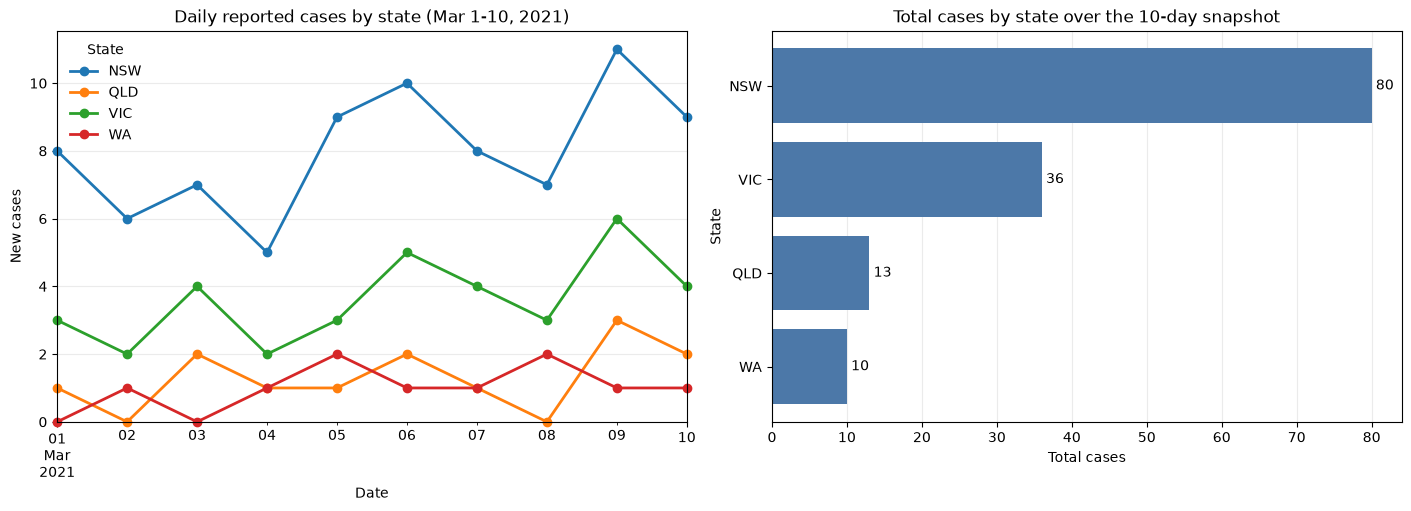

In [9]:
# Task 6 solution
dashboard_path = Path("week2_dashboard.png")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

# Left: how did daily cases change over time in each state?
# clip_on=False keeps markers at zero and at the first/last date fully visible.
daily_cases_wide.plot(ax=axes[0], marker="o", linewidth=2, clip_on=False)
axes[0].set(
    title="Daily reported cases by state (Mar 1-10, 2021)",
    xlabel="Date",
    ylabel="New cases",
)
axes[0].set_ylim(bottom=0)
axes[0].grid(axis="y", alpha=0.25)
axes[0].set_axisbelow(True)
axes[0].legend(title="State", frameon=False)

# Right: which states recorded the most cases? Sorted so the largest bar is on top.
bar_data = state_summary.sort_values("total_cases")
bars = axes[1].barh(bar_data["state"], bar_data["total_cases"], color="#4C78A8")
axes[1].bar_label(bars, padding=3)
axes[1].set(
    title="Total cases by state over the 10-day snapshot",
    xlabel="Total cases",
    ylabel="State",
)
axes[1].grid(axis="x", alpha=0.25)
axes[1].set_axisbelow(True)

fig.savefig(dashboard_path, dpi=150, bbox_inches="tight")
plt.show()

### Task 6 written response

State the analytical question answered by each chart. Identify one design choice you made to improve readability.

- Left (line chart): How did daily new cases change over time in each state from March 1 to March 10, 2021?
- Right (horizontal bar chart): Which states recorded the most cases over the whole 10-day snapshot?

 The bars are sorted from lowest to highest, so the largest state sits at the top and the ranking can be read at a glance. Each bar is labelled with its total, which takes the values from state_summary, so nothing is typed by hand. The light grid lines only on each chart's numeric axis helps with readablility. A zero baseline is on the line chart so differences between states aren't exaggerated. constrained_layout=True is included so titles and labels don't overlap.

## Task 7 — Validate, export, and interpret (8 points)

1. Use assertions to confirm:
   - `duplicate_key_count` is zero;
   - `metadata_key_is_unique` is true;
   - `unmatched_rows` is empty;
   - all `new_cases` values are nonnegative;
   - all `new_tests` values are positive;
   - `cases_per_million` contains no missing values.
2. Export `integrated` to `week2_integrated_cases.csv` without the index.
3. Store the export path in `export_path`.
4. Print the final shape and the paths of both submission files.


In [10]:
# Task 7 solution
assert duplicate_key_count == 0, "Duplicate date-state keys found"
assert metadata_key_is_unique, "Metadata state key is not unique"
assert unmatched_rows.empty, "Some daily rows did not match the metadata"
assert (integrated["new_cases"] >= 0).all(), "Negative case counts found"
assert (integrated["new_tests"] > 0).all(), "Non-positive test counts found"
assert integrated["cases_per_million"].notna().all(), "Missing cases_per_million values"

export_path = Path("week2_integrated_cases.csv")
integrated.to_csv(export_path, index=False)

print("Validation passed.")
print("Final integrated shape:", integrated.shape)
print("Integrated CSV:", export_path.resolve())
print("Dashboard PNG:", dashboard_path.resolve())

Validation passed.
Final integrated shape: (40, 11)
Integrated CSV: D:\Grad School\PrinciplesOfDataScience\ICP-2\src\week2_integrated_cases.csv
Dashboard PNG: D:\Grad School\PrinciplesOfDataScience\ICP-2\src\week2_dashboard.png


### Task 7 written response

In 3–5 sentences, summarize the most important pattern you observed. Include at least one exact value from your output and one limitation of this teaching dataset.

The clearest pattern is how concentrated the cases are. NSW recorded 80 cases over the 10 days, more than VIC, QLD, and WA combined (36 + 13 + 10 = 59). The states also moved somewhat together: NSW's peak of 11, VIC's peak of 6, and QLD's peak of 3 all fell on March 9, while other day to day changes were only a few cases. The main limitation is that this is a fixed, simplified 10-day teaching snapshot of only four states, so these small counts can't support conclusions about real COVID-19 trends or policy.

## Submission self-check

Run this cell after completing every task. Passing it confirms that required variables and files exist, but it does not guarantee full credit for correctness, explanations, or chart quality.


In [11]:
required_variables = [
    "part1",
    "part2",
    "state_metadata",
    "state_benchmarks",
    "input_shapes",
    "combined_cases",
    "duplicate_key_count",
    "metadata_key_is_unique",
    "integrated",
    "unmatched_rows",
    "state_summary",
    "daily_cases_wide",
    "fig",
    "export_path",
]

missing_variables = [
    name for name in required_variables if name not in globals()
]

if missing_variables:
    print("Still missing required variables:")
    for name in missing_variables:
        print(" -", name)
else:
    print("All required variables exist.")

csv_path = Path("week2_integrated_cases.csv")
figure_path = Path("week2_dashboard.png")
print("Integrated CSV exists:", csv_path.exists())
print("Dashboard image exists:", figure_path.exists())

if "combined_cases" in globals():
    print(
        "Combined data has unique date-state keys:",
        not combined_cases.duplicated(["date", "state"]).any(),
    )
if "integrated" in globals():
    print("Integrated rows:", len(integrated))


All required variables exist.
Integrated CSV exists: True
Dashboard image exists: True
Combined data has unique date-state keys: True
Integrated rows: 40


## Optional challenge — Audit function (no extra credit required)

Write `audit_merge(left, right, key)` that returns:

- whether the key is unique in the right table;
- the number of unmatched left rows;
- an outer-merge key audit with an indicator column.

Test it with `combined_cases`, `state_metadata`, and `"state"`.


In [13]:
# Optional challenge
def audit_merge(left, right, key):
    'Report right-key uniqueness, unmatched left rows, and an outer-merge key audit.'
    right_keys = right[[key]].drop_duplicates()

    left_matches = left[[key]].merge(right_keys, on=key, how="left", indicator=True)
    unmatched_left_rows = int((left_matches["_merge"] == "left_only").sum())

    key_audit = (
        left[[key]].drop_duplicates()
        .merge(right_keys, on=key, how="outer", indicator=True)
        .sort_values(key)
        .reset_index(drop=True)
    )

    return {
        "right_key_is_unique": right[key].is_unique,
        "unmatched_left_rows": unmatched_left_rows,
        "key_audit": key_audit,
    }


audit = audit_merge(combined_cases, state_metadata, "state")
print("Right key unique:", audit["right_key_is_unique"])
print("Unmatched left rows:", audit["unmatched_left_rows"])
display(audit["key_audit"])

Right key unique: True
Unmatched left rows: 0


,state,_merge
0,NSW,both
1,NT,right_only
2,QLD,both
3,VIC,both
4,WA,both


## Grading rubric

| Area | Points | Full-credit evidence |
|---|---:|---|
| Task 1: Load and inspect | 6 | Correct parsing, shapes, previews, date ranges, and grain explanation |
| Task 2: Concatenate | 8 | Correct row-wise concatenation, order, index, row validation, and duplicate check |
| Task 3: Merge metadata | 10 | Key uniqueness checked, validated merge, indicator audit, and accurate explanation |
| Task 4: Join and derive | 8 | Correct indexed join, rates, target comparison, and interpretation |
| Task 5: Aggregate and reshape | 8 | Accurate grouped summary, sorting, pivot, and evidence-based response |
| Task 6: Visualize | 12 | Two accurate, readable charts calculated from data and saved correctly |
| Task 7: Validate and export | 8 | Assertions pass, CSV exported, files reported, and interpretation completed |
| **Total** | **60** | |

Code should be readable, use meaningful names, and avoid unnecessary repetition.
